In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import cyipopt

ModuleNotFoundError: No module named 'jax'

In [2]:
# global constants
g = 9.81 # gravity(m/s^2)
m1 = m2 = 1 # mass of the two "spheres" of the pendulum(kg)
l1 = l2 = 0.5 # pendulum lengths(m)
dt = 0.05 # discretization time

u_min   = -10.0 # min control
u_max   = 10.0  # max control

def dynamics(x, u):
    q1, q2, q1_dot, q2_dot = x
    u1, u2 = u
    q_dot = jnp.array([q1_dot, q2_dot])
    
    # Forward dynamics matrices (for the q_ddot)
    M = jnp.array([
        [l1**2 * m1 + l2**2 * m2 + l1**2 * m2 + 2*l1*m2*l2*jnp.cos(q2), l2**2 * m2 + l1*m2*l2*jnp.cos(q2)],
        [l2**2 * m2 + l1*m2*l2*jnp.cos(q2), l2**2 * m2]
    ])

    C = jnp.array([
        [-2*q2_dot*l1*m2*l2*jnp.sin(q2), -q2_dot*l1*m2*l2*jnp.sin(q2)],
        [q1_dot*l1*m2*l2*jnp.sin(q2), 0]
    ])

    G = jnp.array([
        -g*m1*l1*jnp.sin(q1) - g*m2*(l1*jnp.sin(q1) + l2*jnp.sin(q1 + q2)), -g*m2*l2*jnp.sin(q1 + q2)
    ])

    # Forward dynamics
    b = jnp.array([u1, u2]) - C @ q_dot + G
    q_ddot = jnp.linalg.solve(M, b)
    q1_ddot, q2_ddot = q_ddot

    x_dot = jnp.array([q1_dot, q2_dot, q1_ddot, q2_ddot])
    return x_dot

In [3]:
def rk4(x, u):
    f1 = dynamics(x, u)
    f2 = dynamics(x + f1*dt/2, u)
    f3 = dynamics(x + f2*dt/2, u)
    f4 = dynamics(x + f3*dt, u)

    x_n = x + (dt/6) * (f1 + 2*f2 + 2*f3 + f4) # next discretized state
    return x_n

# Discretize f
def f_discrete(x, u):
    return rk4(x, u)

In [4]:
# Simulation Data
T = 5 # simulation time
K = 100
print("K =", K)

K = 100


In [5]:
# Helper variables
N = 4 # state size
M = 2 # control input
h = dt # t_k+1 - t_k

x0 = jnp.array([0, 0, 0, 0])
xf = jnp.array([jnp.pi, 0, 0, 0])

In [6]:
# Objective - Minimal Control Effort
def objective(z):
    offset = (K + 1) * N # we skip over the states
    U = z[offset: offset + (K + 1) * M].reshape((K+1, M))

    J = jnp.sum(U**2) * dt
    return J

In [7]:
def herm_simps_constraints(xk, xk1, xm, uk, uk1, um):
    fk = dynamics(xk, uk)
    fk1 = dynamics(xk1, uk1)
    fm = dynamics(xm, um)

    # Simpson constraint
    c1 = xk1 - xk - (h/6) * (fk + 4*fm + fk1)
    # Hermite midpoint constraint
    c2 = xm - 0.5 * (xk1 + xk) - (h/8) * (fk - fk1)
    
    return jnp.concatenate([c1, c2])

# Constraints function
def constraints(z):
    c = [] # Initialize

    # Extract knot and middle points
    idx = 0
    X = z[idx : idx + (K + 1) * N].reshape((K+1, N)) # extract all states x0, x1, ..., xk     (K+1)xN vector
    idx += (K + 1) * N # Finished extracting states x, moving on (to controls u)  

    U = z[idx : idx + (K + 1) * M].reshape((K+1, M)) # extract all controls u0, u1, ..., uk     (K+1)xM vector
    idx += (K + 1) * M # Finished extracting controls u, moving on (to middle points xm)

    Xm = z[idx : idx + K * N].reshape((K, N)) # extract all middle states xm    KxN vector
    idx += K * N

    Um = z[idx : idx + K * M].reshape((K, M)) # extract all middle controls um    KxM vector

    defects = jax.vmap(herm_simps_constraints)(             # shape (K, 2*N)
        X[:-1], X[1:], Xm,      # States: k, k+1, mid
        U[:-1], U[1:], Um       # Controls: k, k+1, mid
    )
    
    # Boundary constraints
    x0_constr = X[0] - jnp.array([0., 0., 0., 0.])
    xf_constr = X[-1] - jnp.array([jnp.pi, 0., 0., 0.])

    return jnp.concatenate([x0_constr, xf_constr, defects.flatten()])

In [8]:
# For faster JAX
jit_objective = jax.jit(objective)
jit_gradient = jax.jit(jax.grad(objective))
jit_constraints = jax.jit(constraints)
jit_jacobian = jax.jit(jax.jacfwd(constraints))

n_vars = (K+1)*(N+M) + K*(N+M)
m = constraints(jnp.zeros(n_vars)).size

# Use random data to ensure we don't accidentally get zeros that are actually structurally non-zero.
z_random = np.random.randn(n_vars)
J_dense = np.array(jit_jacobian(z_random))

# Find indices where Jacobian is NOT zero
J_rows, J_cols = np.nonzero(np.abs(J_dense) > 1e-9)
num_nonzero = len(J_rows)

class TrajOpt:
    def objective(self, z):
        return float(jit_objective(z))

    def gradient(self, z):
        return np.array(jit_gradient(z), dtype=np.float64).flatten()

    def constraints(self, z):
        return np.array(jit_constraints(z), dtype=np.float64).flatten()

    def jacobian(self, z):
        J = np.array(jit_jacobian(z), dtype=np.float64)
        return J[J_rows, J_cols]
    
    def jacobianstructure(self):
        return (J_rows, J_cols)
    
    def intermediate(self, alg_mod, iter_count, obj_value, inf_pr, inf_du, mu,
                     d_norm, regularization_size, alpha_du, alpha_pr, ls_trials):
        
        msg = "Iter #{:d} | Obj: {:.5g} | Infeasibility: {:.5g}"

        print(msg.format(iter_count, obj_value, inf_pr))

In [9]:
lb = -np.inf * np.ones(n_vars)
ub =  np.inf * np.ones(n_vars)

cl = np.zeros(m)
cu = np.zeros(m)

# Constrain controls
u_start = (K+1)*N
u_end = u_start + (K+1)*M
lb[u_start:u_end] = -10.0
ub[u_start:u_end] =  10.0

# Constrain middle controls as well
um_start = u_end + K*N
um_end = um_start + K*M
lb[um_start:um_end] = -10.0
ub[um_start:um_end] =  10.0

z0 = np.zeros(n_vars)

nlp = cyipopt.Problem(
    n=n_vars,
    m=m,
    problem_obj=TrajOpt(),
    lb=lb,
    ub=ub,
    cl=cl,
    cu=cu
)

nlp.add_option("max_iter", 500)
nlp.add_option("tol", 1e-5)
nlp.add_option("print_level", 5)

z_opt, info = nlp.solve(z0)

# Check the numerical status code
if info['status'] == 0:
    print("SUCCESS: Optimal Solution Found!")
else:
    print(f"FAILURE: Solver failed with status {info['status']}")

NameError: name 'cyipopt' is not defined

In [10]:
# Extract nominal knot points form ipopt
X_nom = z_opt[0 : (K + 1) * N].reshape((K + 1, N))
U_nom = z_opt[(K + 1) * N : (K + 1) * (N + M)].reshape((K + 1, M))

NameError: name 'z_opt' is not defined

In [11]:
# State and control weights
Q = np.diag([10, 1000, 1, 10]) 
R = np.diag([0.001, 0.001])
QN = np.diag([100, 100, 100, 100]) # Final state cost

# Initialize
Ps = [np.zeros((N, N))]*(K + 1)
Ks = [np.zeros((M, N))]*K

# Wrapper for RK4 to differentiate w.r.t x and u
rk4_jax = jax.jit(rk4)

get_A = jax.jit(jax.jacfwd(rk4_jax, 0)) # df/dx
get_B = jax.jit(jax.jacfwd(rk4_jax, 1)) # df/du

As = jax.vmap(get_A)(X_nom[:-1], U_nom[:-1])
Bs = jax.vmap(get_B)(X_nom[:-1], U_nom[:-1])

print(f"Linearized Model Shapes: A={As.shape}, B={Bs.shape}")

def tvlqr(As, Bs, Q, R, QN):
    K_gains = []
    P = QN # Start with final cost
    
    # Backward pass 
    for k in range(K-1, -1, -1):
        A = As[k]
        B = Bs[k]
        
        # K_k = -(R + B'PB)^-1 B'PA
        inv_term = jnp.linalg.inv(R + B.T @ P @ B)
        K_k = -inv_term @ B.T @ P @ A
        
        # P_k = Q + A'PA + A'PB K_k
        P = Q + A.T @ P @ A + A.T @ P @ B @ K_k
        
        K_gains.insert(0, K_k) # Store K gains in correct order
    return jnp.array(K_gains)

K_gains = tvlqr(As, Bs, Q, R, QN)

NameError: name 'X_nom' is not defined

In [12]:
def solve_infinite_horizon_lqr(A, B, Q, R, QN, tolerance=1e-6):
    P = QN
    for _ in range(K):
        # Riccati iteration
        P_next = Q + A.T @ P @ A - (A.T @ P @ B) @ jnp.linalg.inv(R + B.T @ P @ B) @ (B.T @ P @ A)
        
        # Check for convergence
        if jnp.max(jnp.abs(P_next - P)) < tolerance:
            break
        P = P_next
        
    # Calculate final steady-state gain
    K_inf = -jnp.linalg.inv(R + B.T @ P @ B) @ B.T @ P @ A
    return K_inf

# Linearize at the equilibrium point(top vertical)
A_top = get_A(xf, jnp.zeros(M))
B_top = get_B(xf, jnp.zeros(M))

K_inf = solve_infinite_horizon_lqr(A_top, B_top, Q, R, QN)

def my_controller(x_measured, k):
    
    # Stabilization after trajectory ends
    if k >= K:
        x_target = jnp.array([jnp.pi, 0, 0, 0])
        # We use the steady-state K_inf here
        error = x_measured - x_target
        return K_inf @ error # Feedforward u_nom is zero at equilibrium
        
    # Nominal values for any timestep
    x_nom = X_nom[k]
    u_nom = U_nom[k]
    K_k = K_gains[k] # Gain at time k
    
    error = x_measured - x_nom # Error because of noise
    
    # Feedback law
    u_feedback = K_k @ error
    return u_nom + u_feedback # nominal (without noise) + feedback (for correction)

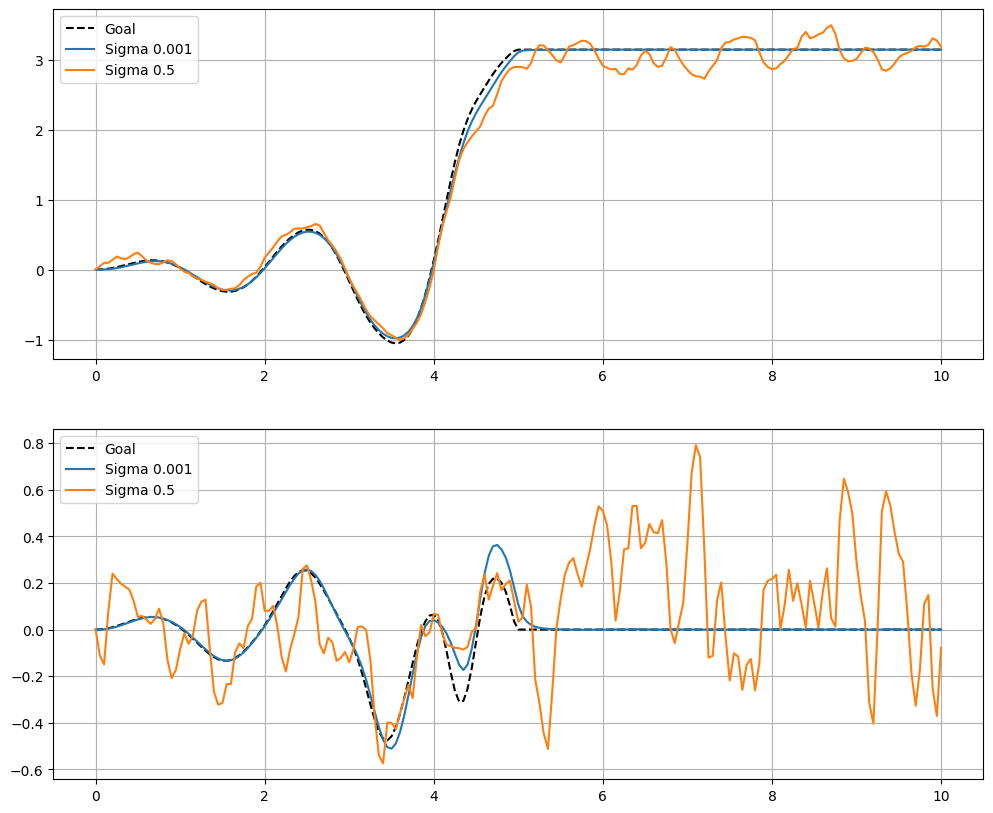

In [16]:
# Setup extended parameters 
extra_steps = 100 # Extra steps for when the trajectory ends
total_steps = K + extra_steps  # 100 + 100 = 200

# Extend the nominal points 
extense_X = jnp.tile(xf, (extra_steps, 1))
X_nom_extended = jnp.vstack([X_nom, extense_X])

extense_U = jnp.zeros((extra_steps, M))
U_nom_extended = jnp.vstack([U_nom, extense_U])

# Simulation with different noise levels and extended time
noise_levels = [0.001, 0.5]
results = []

for sigma in noise_levels:
    x_history = [x0]
    u_history = []
    x_curr = x0
    
    for k in range(total_steps):
        noise = np.random.normal(0, sigma, N) # Gaussian noise
        x_measured = x_curr + noise # Observed state with noise
        
        u = my_controller(x_measured, k) # Control input with noise
        x_curr = rk4(x_curr, u)
        
        x_history.append(x_curr)
        u_history.append(u)
        
    results.append((sigma, jnp.array(x_history), jnp.array(u_history)))

# Plots for both noise levels
t_plot = np.linspace(0, total_steps * dt, total_steps + 1)

plt.figure(figsize=(12, 10))
# Plot q1
plt.subplot(2, 1, 1)
plt.plot(t_plot, X_nom_extended[:, 0], 'k--', label="Goal")
for sigma, x_res, _ in results:
    plt.plot(t_plot, x_res[:, 0], label=f"Sigma {sigma}")
plt.legend()
plt.grid(True)

# Plot q2
plt.subplot(2, 1, 2)
plt.plot(t_plot, X_nom_extended[:, 1], 'k--', label="Goal")
for sigma, x_res, _ in results:
    plt.plot(t_plot, x_res[:, 1], label=f"Sigma {sigma}")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Animation of the double pendulum for both noise levels
# results[0] is low noise, results[1] is high noise
def get_coords(x_res):
    q1, q2 = x_res[:, 0], x_res[:, 1]
    x1 = l1 * np.sin(q1)
    y1 = -l1 * np.cos(q1)
    x2 = x1 + l2 * np.sin(q1 + q2)
    y2 = y1 - l2 * np.cos(q1 + q2)
    return x1, y1, x2, y2

# Extract coordinates for both
x1_low, y1_low, x2_low, y2_low = get_coords(results[0][1])
x1_high, y1_high, x2_high, y2_high = get_coords(results[1][1])

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect('equal')
ax.grid(True)

line_low, = ax.plot([], [], 'o-', lw=3, label=f'Noise $\sigma$={results[0][0]}', color='tab:blue') # Low Noise (Blue)
line_high, = ax.plot([], [], 'o-', lw=3, label=f'Noise $\sigma$={results[1][0]}', color='tab:orange') # High Noise (Orange)

time_text = ax.text(0.05, 0.9, '', transform=ax.transAxes)
ax.legend(loc='lower right')

def init():
    line_low.set_data([], [])
    line_high.set_data([], [])
    time_text.set_text('')
    return line_low, line_high, time_text

def animate(i):
    line_low.set_data([0, x1_low[i], x2_low[i]], [0, y1_low[i], y2_low[i]]) # Update low noise pendulum
    line_high.set_data([0, x1_high[i], x2_high[i]], [0, y1_high[i], y2_high[i]]) # Update high noise pendulum
    time_text.set_text(f"Time: {i*0.05:.2f}s") # Update time
    return line_low, line_high, time_text

# Create animation
ani = FuncAnimation(fig, animate, frames=len(x1_low), interval=50, blit=True, init_func=init)

plt.close()
HTML(ani.to_jshtml())

<>:25: SyntaxWarning: invalid escape sequence '\s'
<>:26: SyntaxWarning: invalid escape sequence '\s'
<>:25: SyntaxWarning: invalid escape sequence '\s'
<>:26: SyntaxWarning: invalid escape sequence '\s'
C:\Users\Κωνσταντίνος\AppData\Local\Temp\ipykernel_25908\2843267620.py:25: SyntaxWarning: invalid escape sequence '\s'
  line_low, = ax.plot([], [], 'o-', lw=3, label=f'Noise $\sigma$={results[0][0]}', color='tab:blue') # Low Noise (Blue)
C:\Users\Κωνσταντίνος\AppData\Local\Temp\ipykernel_25908\2843267620.py:26: SyntaxWarning: invalid escape sequence '\s'
  line_high, = ax.plot([], [], 'o-', lw=3, label=f'Noise $\sigma$={results[1][0]}', color='tab:orange') # High Noise (Orange)
